# Rede neural MLP para o Adult

Este notebook contém somente a preparação necessária, o treinamento e a
avaliação da rede neural para prever `income` (`<=50K` ou `>50K`).
Mantém os mesmos hiperparâmetros, 13 preditores e divisão estratificada 70/30. Não há ajuste de parâmetros pelo teste.

A caracterização completa dos dados e a comparação entre métodos estão em
[caracterizacaoComparacaoAdult.ipynb](caracterizacaoComparacaoAdult.ipynb).


## 1. Bibliotecas e configuração

In [2]:
!pip install ucimlrepo

In [3]:
import os
import sys
from importlib.metadata import version
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["MKL_NUM_THREADS"] = "2"
os.environ["OPENBLAS_NUM_THREADS"] = "2"

import json
import hashlib
import platform
from datetime import datetime, timezone
from pathlib import Path
from time import perf_counter
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits, threadpool_info
from ucimlrepo import fetch_ucirepo
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, make_scorer,
)
from sklearn.exceptions import ConvergenceWarning

SEED = 42
CLASSES = ["<=50K", ">50K"]
CODIGO_CLASSES = {"<=50K": 0, ">50K": 1}
target_column = "income"
np.random.seed(SEED)
_limite_threads = threadpool_limits(limits=2)
sns.set_theme(style="whitegrid", palette="Blues_r")
get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12})
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_columns", 20)

VERSOES = {
    pacote: version(pacote)
    for pacote in ("numpy", "pandas", "scikit-learn", "matplotlib", "seaborn", "ucimlrepo")
}

## 2. Carregamento e limpeza para treinamento

Usamos o [Adult da UCI](https://archive.ics.uci.edu/dataset/2/adult), cujo alvo é
`income`. Retiramos espaços e o ponto final dos rótulos, convertemos `?` em
ausente e removemos registros sem alvo. Esses passos não aprendem parâmetros.
A exploração completa dos atributos está no notebook de análise separado.

In [ ]:
adult = fetch_ucirepo(id=2)
dataset_original = pd.concat([adult.data.features, adult.data.targets], axis=1).copy()
dataset_original.columns = dataset_original.columns.str.strip()
assert dataset_original.shape == (48842, 15), "A fonte mudou: revisar antes da comparação."
assert target_column in dataset_original.columns
hash_fonte = hashlib.sha256(dataset_original.to_csv(index=False).encode("utf-8")).hexdigest()
print("Formato original:", dataset_original.shape)
print("SHA-256 da representação CSV recebida:", hash_fonte)
display(dataset_original.head())

Formato original: (48842, 15)
SHA-256 da representação CSV recebida: 7bf09a7484d84f92c7e69582078bb01b2f7c4862c8fb27990c0dd848a8a029f4


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [ ]:
dataset = dataset_original.copy()
for col in dataset.select_dtypes(include=["object", "string"]).columns:
    dataset[col] = dataset[col].str.strip()
dataset = dataset.replace("?", np.nan)
dataset[target_column] = dataset[target_column].str.replace(r"\.$", "", regex=True)
sem_alvo = int(dataset[target_column].isna().sum())
dataset = dataset.dropna(subset=[target_column]).copy()
assert set(dataset[target_column].unique()) == set(CLASSES)
print("Registros removidos por ausência de alvo:", sem_alvo)

Registros removidos por ausência de alvo: 0


## 3. Preparação e mesma divisão de treino e teste da árvore

Removemos somente `fnlwgt`, mantendo as outras 13 entradas, inclusive `education`
e `education-num`, que codificam aspectos relacionados da escolaridade.
Não removemos duplicatas para preservar os registros e índices do notebook de referência;
uma futura avaliação com deduplicação exigiria repetir todos os algoritmos sob esse protocolo.

Aplicamos mediana nas cinco entradas numéricas e moda nas oito categóricas.
O `StandardScaler` padroniza as numéricas; o `OneHotEncoder` transforma categorias em
indicadores binários e ignora categorias novas no teste.
Todo ajuste dessas transformações ocorre dentro de cada conjunto de treino.

In [ ]:
X = dataset.drop(columns=[target_column, "fnlwgt"])
y = dataset[target_column]
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()
print("Variáveis numéricas:", numeric_features)
print("Variáveis categóricas:", categorical_features)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
assert X_train.index.intersection(X_test.index).empty
assert (X_train.shape, X_test.shape) == ((34189, 13), (14653, 13))
print("Dados de treinamento:", X_train.shape)
print("Dados de teste:", X_test.shape)
distribuicao_split = pd.DataFrame({
    "Treino (n)": y_train.value_counts().reindex(CLASSES),
    "Treino (%)": y_train.value_counts(normalize=True).reindex(CLASSES) * 100,
    "Teste (n)": y_test.value_counts().reindex(CLASSES),
    "Teste (%)": y_test.value_counts(normalize=True).reindex(CLASSES) * 100,
})
display(distribuicao_split.style.format({"Treino (%)": "{:.2f}%", "Teste (%)": "{:.2f}%"}))
hash_indices_teste = hashlib.sha256(np.asarray(X_test.index, dtype="int64").tobytes()).hexdigest()
print("SHA-256 dos índices de teste, na ordem de avaliação:", hash_indices_teste)

Variáveis numéricas: ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Variáveis categóricas: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
Dados de treinamento: (34189, 13)
Dados de teste: (14653, 13)


,Treino (n),Treino (%),Teste (n),Teste (%)
income,,,,
<=50K,26008,76.07%,11147,76.07%
>50K,8181,23.93%,3506,23.93%


SHA-256 dos índices de teste, na ordem de avaliação: 74d268808db0373e64c3f42e364d26fb72966f4dfc5919061262ee4e4533c6ba


## 4. Rede neural e protocolo de avaliação

Usamos um **MLP com duas camadas ocultas, de 64 e 32 neurônios**, ativação ReLU,
otimizador Adam e regularização L2 (`alpha=0.001`). A saída binária utiliza função
logística. Os pesos são aprendidos por retropropagação do erro.

O limite é 200 épocas, com lotes de 256 exemplos e taxa inicial de aprendizado 0,001.
No ajuste da rede, codificamos o alvo como `<=50K = 0` e `>50K = 1`.
Essa transformação é fixa e não aprende informação do teste. As previsões são
decodificadas para os rótulos originais na avaliação e nas tabelas.
O `early_stopping` reserva 15% do treino de cada ajuste para validação interna,
monitora a acurácia e restaura os pesos de melhor validação. Interrompe após 15 épocas
sem melhora suficiente (`tol=0.0001`). Essa validação interna recebe transformações
estimadas no treino externo completo; o teste externo e a validação cruzada externa
permanecem fora do ajuste de imputação, categorias e escala.

Primeiro fazemos validação cruzada estratificada de **3 partes apenas nos 70% de treino**,
refazendo o pipeline em cada parte. Isso fornece média e desvio padrão entre partições.
Depois ajustamos um novo pipeline no treino completo e o avaliamos uma vez nos 30%
de teste da árvore. Não há busca de hiperparâmetros nem escolha de limiar pelo teste.

Precisão, recall e F1 são apresentados para a classe positiva **`>50K`**, como no
notebook existente, e também nas médias macro e ponderada. Média macro significa
peso igual para as duas classes; média ponderada usa seus suportes. Isso é diferente
de tirar a média de resultados entre as partes da validação cruzada.

In [ ]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
])
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features),
], sparse_threshold=1.0)
clf = MLPClassifier(
    hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
    alpha=0.001, batch_size=256, learning_rate_init=0.001,
    max_iter=200, early_stopping=True, validation_fraction=0.15,
    n_iter_no_change=15, tol=1e-4, random_state=SEED,
)
model_template = Pipeline([("preprocessor", preprocessor), ("classifier", clf)])

def calcular_metricas(real, previsto):
    resultado = {"Acurácia": accuracy_score(real, previsto)}
    for nome, funcao in [("Precisão", precision_score), ("Recall", recall_score), ("F1", f1_score)]:
        resultado[f"{nome} (>50K)"] = funcao(real, previsto, pos_label=">50K", zero_division=0)
        resultado[f"{nome} macro"] = funcao(real, previsto, average="macro", zero_division=0)
        resultado[f"{nome} ponderado"] = funcao(real, previsto, average="weighted", zero_division=0)
    return resultado

def ajustar_pipeline(template, entradas, alvo):
    modelo = clone(template)
    inicio = perf_counter()
    matriz = modelo.named_steps["preprocessor"].fit_transform(entradas, alvo)
    tempo_pre = perf_counter() - inicio
    inicio_rede = perf_counter()
    with warnings.catch_warnings(record=True) as capturados:
        warnings.simplefilter("always", ConvergenceWarning)
        modelo.named_steps["classifier"].fit(matriz, alvo.map(CODIGO_CLASSES).to_numpy())
    tempo_rede = perf_counter() - inicio_rede
    tempo_total = perf_counter() - inicio
    avisos = [str(w.message) for w in capturados]
    return modelo, tempo_pre, tempo_rede, tempo_total, avisos

In [ ]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
linhas_cv = []
avisos_treino = []
for parte, (idx_ajuste, idx_validacao) in enumerate(cv.split(X_train, y_train), start=1):
    modelo_cv, t_pre, t_rede, t_total, avisos = ajustar_pipeline(
        model_template, X_train.iloc[idx_ajuste], y_train.iloc[idx_ajuste]
    )
    pred_cv = np.asarray(CLASSES)[modelo_cv.predict(X_train.iloc[idx_validacao])]
    linhas_cv.append({
        "Parte": parte, **calcular_metricas(y_train.iloc[idx_validacao], pred_cv),
        "Tempo pré-processamento (s)": t_pre, "Tempo rede (s)": t_rede,
        "Tempo treino total (s)": t_total,
        "Épocas": modelo_cv.named_steps["classifier"].n_iter_,
    })
    avisos_treino.extend(avisos)
    print(f"Parte {parte}/3 concluída em {t_total:.2f} s.", flush=True)
resultados_cv = pd.DataFrame(linhas_cv).set_index("Parte")
resumo_cv = resultados_cv.agg(["mean", "std"]).T.rename(columns={"mean": "Média", "std": "Desvio padrão"})
display(resultados_cv.round(4))
display(resumo_cv.round(4))
print("Desvio padrão amostral entre 3 partes; não é intervalo de confiança.")

Parte 1/3 concluída em 2.74 s.


Parte 2/3 concluída em 4.24 s.


Parte 3/3 concluída em 5.88 s.


,Acurácia,Precisão (>50K),Precisão macro,Precisão ponderado,Recall (>50K),Recall macro,Recall ponderado,F1 (>50K),F1 macro,F1 ponderado,Tempo pré-processamento (s),Tempo rede (s),Tempo treino total (s),Épocas
Parte,,,,,,,,,,,,,,
1,0.8549,0.7288,0.8082,0.8496,0.6267,0.7767,0.8549,0.6739,0.7903,0.8510,0.1155,2.6265,2.7420,19
2,0.8551,0.7452,0.8133,0.8488,0.5996,0.7675,0.8551,0.6645,0.7861,0.8494,0.0880,4.1515,4.2394,30
3,0.8532,0.7199,0.8043,0.8483,0.6326,0.7776,0.8532,0.6734,0.7894,0.8498,0.0969,5.7857,5.8826,42


,Média,Desvio padrão
Acurácia,0.8544,0.0010
Precisão (>50K),0.7313,0.0128
Precisão macro,0.8086,0.0045
Precisão ponderado,0.8489,0.0006
Recall (>50K),0.6196,0.0176
Recall macro,0.7739,0.0056
Recall ponderado,0.8544,0.0010
F1 (>50K),0.6706,0.0053
F1 macro,0.7886,0.0022
F1 ponderado,0.8501,0.0008


Desvio padrão amostral entre 3 partes; não é intervalo de confiança.


In [ ]:
model, tempo_pre, tempo_rede, tempo_total, avisos = ajustar_pipeline(model_template, X_train, y_train)
avisos_treino.extend(avisos)
rede = model.named_steps["classifier"]
n_entradas = model.named_steps["preprocessor"].get_feature_names_out().size
n_parametros = sum(p.size for p in rede.coefs_) + sum(p.size for p in rede.intercepts_)
print(f"Arquitetura após one-hot: {n_entradas} → 64 → 32 → 1")
print(f"Parâmetros treináveis: {n_parametros:,}")
print(f"Épocas executadas: {rede.n_iter_}")
print(f"Melhor acurácia na validação interna: {rede.best_validation_score_:.4f}")
print(f"Tempo de pré-processamento: {tempo_pre:.4f} s")
print(f"Tempo de ajuste da rede: {tempo_rede:.4f} s")
print(f"Tempo de treinamento do pipeline completo: {tempo_total:.4f} s")
print("Avisos durante os ajustes:", avisos_treino if avisos_treino else "nenhum")

Arquitetura após one-hot: 104 → 64 → 32 → 1
Parâmetros treináveis: 8,833
Épocas executadas: 19
Melhor acurácia na validação interna: 0.8559
Tempo de pré-processamento: 0.1347 s
Tempo de ajuste da rede: 4.0182 s
Tempo de treinamento do pipeline completo: 4.1529 s
Avisos durante os ajustes: nenhum


In [ ]:
colunas_metricas = ["Acurácia", "Precisão (>50K)", "Recall (>50K)", "F1 (>50K)", "Tempo treino total (s)"]
tabela_media = pd.DataFrame([{
    "Algoritmo": "Rede neural MLP", "Protocolo": "CV 3 partes nos 70% de treino",
    **{coluna: f"{resumo_cv.loc[coluna, 'Média']:.4f} ± {resumo_cv.loc[coluna, 'Desvio padrão']:.4f}"
       for coluna in colunas_metricas},
}])
display(tabela_media)

,Algoritmo,Protocolo,Acurácia,Precisão (>50K),Recall (>50K),F1 (>50K),Tempo treino total (s)
0,Rede neural MLP,CV 3 partes nos 70% de treino,0.8544 ± 0.0010,0.7313 ± 0.0128,0.6196 ± 0.0176,0.6706 ± 0.0053,4.2880 ± 1.5709


## 5. Previsões e métricas da rede neural

As primeiras 20 previsões seguem a mesma ordem do teste, e as linhas da matriz
representam a classe real. O critério de decisão é o padrão do classificador,
equivalente a 0,5 para a probabilidade binária, sem ajuste posterior pelo teste.

In [ ]:
inicio_predicao = perf_counter()
y_pred = np.asarray(CLASSES)[model.predict(X_test)]
tempo_predicao = perf_counter() - inicio_predicao
resultados = pd.DataFrame({"Valor Real": y_test.to_numpy(), "Valor Previsto": y_pred})
display(resultados.head(20))

metricas_teste = calcular_metricas(y_test, y_pred)
accuracy = metricas_teste["Acurácia"]
precision = metricas_teste["Precisão (>50K)"]
recall = metricas_teste["Recall (>50K)"]
f1 = metricas_teste["F1 (>50K)"]
print("AVALIAÇÃO DO MODELO — REDE NEURAL MLP")
print(f"Acurácia: {accuracy:.4f}")
print(f"Precisão: {precision:.4f}")
print(f"Recall:   {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"Tempo de treino completo: {tempo_total:.4f} s")
print(f"Tempo de predição: {tempo_predicao:.4f} s")
print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred, labels=CLASSES, digits=4, zero_division=0))
relatorio_classes = pd.DataFrame(classification_report(
    y_test, y_pred, labels=CLASSES, output_dict=True, zero_division=0
)).T
display(relatorio_classes.round(4))
display(pd.DataFrame([{
    "Algoritmo": "Rede neural MLP", "Acurácia": accuracy,
    "Precisão (>50K)": precision, "Recall (>50K)": recall,
    "F-Measure (>50K)": f1, "Tempo de processamento (s)": tempo_total,
}]).round(4))

,Valor Real,Valor Previsto
0,<=50K,<=50K
1,<=50K,<=50K
2,<=50K,<=50K
3,<=50K,<=50K
4,<=50K,<=50K
5,<=50K,<=50K
6,>50K,>50K
7,<=50K,<=50K
8,<=50K,>50K
9,<=50K,<=50K


AVALIAÇÃO DO MODELO — REDE NEURAL MLP
Acurácia: 0.8563
Precisão: 0.7385
Recall:   0.6187
F1-Score: 0.6733
Tempo de treino completo: 4.1529 s
Tempo de predição: 0.0633 s

Relatório de classificação:
              precision    recall  f1-score   support

       <=50K     0.8859    0.9311    0.9079     11147
        >50K     0.7385    0.6187    0.6733      3506

    accuracy                         0.8563     14653
   macro avg     0.8122    0.7749    0.7906     14653
weighted avg     0.8506    0.8563    0.8518     14653



,precision,recall,f1-score,support
<=50K,0.8859,0.9311,0.9079,11147.0000
>50K,0.7385,0.6187,0.6733,3506.0000
accuracy,0.8563,0.8563,0.8563,0.8563
macro avg,0.8122,0.7749,0.7906,14653.0000
weighted avg,0.8506,0.8563,0.8518,14653.0000


,Algoritmo,Acurácia,Precisão (>50K),Recall (>50K),F-Measure (>50K),Tempo de processamento (s)
0,Rede neural MLP,0.8563,0.7385,0.6187,0.6733,4.1529


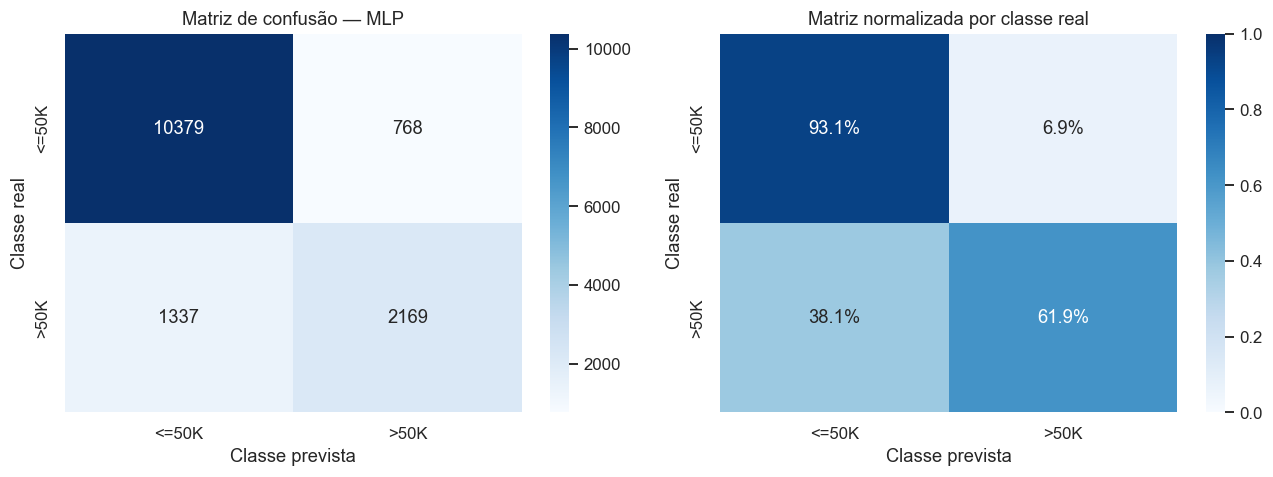

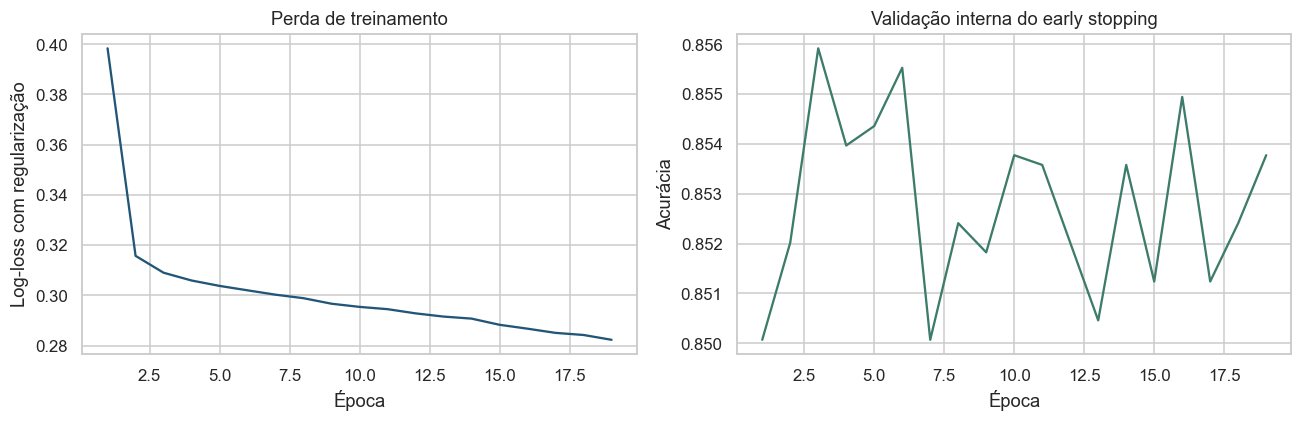

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=CLASSES)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES,
            yticklabels=CLASSES, ax=axes[0])
axes[0].set(title="Matriz de confusão — MLP", xlabel="Classe prevista", ylabel="Classe real")
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".1%", cmap="Blues",
            vmin=0, vmax=1, xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
axes[1].set(title="Matriz normalizada por classe real", xlabel="Classe prevista", ylabel="Classe real")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epocas = np.arange(1, len(rede.loss_curve_) + 1)
axes[0].plot(epocas, rede.loss_curve_, color="#225577")
axes[0].set(title="Perda de treinamento", xlabel="Época", ylabel="Log-loss com regularização")
axes[1].plot(epocas, rede.validation_scores_, color="#3d7b6a")
axes[1].set(title="Validação interna do early stopping", xlabel="Época", ylabel="Acurácia")
plt.tight_layout()
plt.show()

## 6. Relevância das variáveis originais

O MLP não fornece `feature_importances_`. Por isso, permutamos cada coluna original
e medimos a queda do F1 de `>50K` ao perturbar sua informação, atravessando o pipeline
completo. Assim, todas as categorias de uma variável são tratadas em conjunto.
Usamos amostra estratificada de até 2.000 registros de teste e cinco permutações por
atributo para limitar o custo.

A tabela ocupa a mesma função descritiva da tabela de importância da árvore,
mas a escala é **queda em pontos percentuais de F1**, não percentual de importância
que soma 100%. Valores negativos são mantidos; podem decorrer da amostragem ou de ruído.
Variáveis correlacionadas podem compartilhar ou mascarar sua relevância. Esta análise
é posterior à avaliação e não é usada para selecionar variáveis ou reajustar o modelo.

Variável Original,Queda média F1 (p.p.),Desvio padrão (p.p.)
marital-status,13.16,1.01
education-num,8.39,1.38
capital-gain,6.51,1.05
age,5.13,0.94
occupation,4.85,0.87
relationship,4.70,0.74
hours-per-week,3.27,0.73
workclass,1.19,0.46
capital-loss,1.14,0.47
sex,1.02,0.45


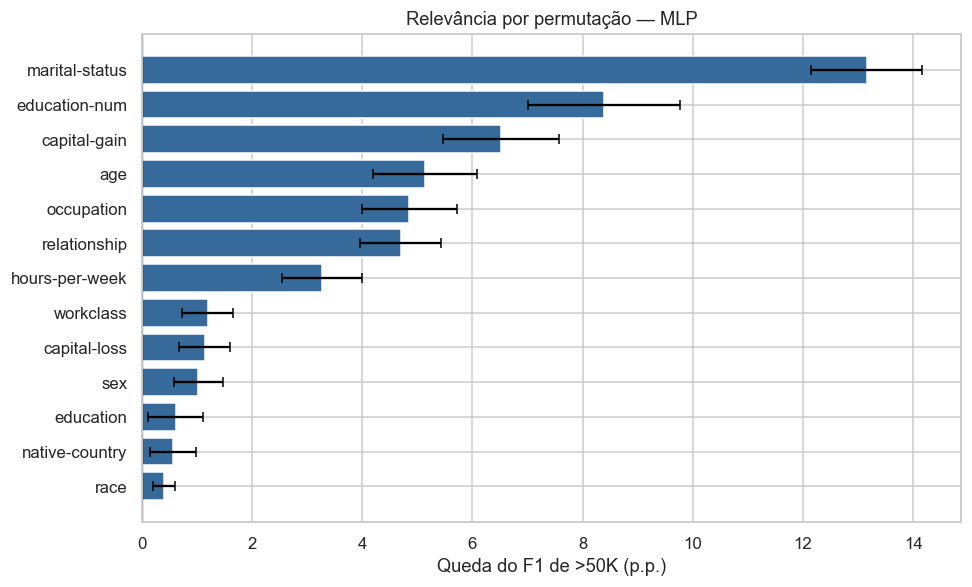

In [ ]:
if len(X_test) > 2000:
    X_imp, _, y_imp, _ = train_test_split(
        X_test, y_test, train_size=2000, random_state=SEED, stratify=y_test
    )
else:
    X_imp, y_imp = X_test, y_test
scorer_f1 = make_scorer(f1_score, pos_label=1, zero_division=0)
permutacao = permutation_importance(
    model, X_imp, y_imp.map(CODIGO_CLASSES), scoring=scorer_f1,
    n_repeats=5, random_state=SEED, n_jobs=1
)
importance_grouped = pd.DataFrame({
    "Variável Original": X.columns,
    "Queda média F1 (p.p.)": permutacao.importances_mean * 100,
    "Desvio padrão (p.p.)": permutacao.importances_std * 100,
}).sort_values("Queda média F1 (p.p.)", ascending=False).reset_index(drop=True)
display(importance_grouped.style.format({
    "Queda média F1 (p.p.)": "{:.2f}", "Desvio padrão (p.p.)": "{:.2f}",
}).background_gradient(subset=["Queda média F1 (p.p.)"], cmap="Blues").hide(axis="index"))
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(importance_grouped["Variável Original"], importance_grouped["Queda média F1 (p.p.)"],
        xerr=importance_grouped["Desvio padrão (p.p.)"], color="#356a9a", capsize=3)
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Relevância por permutação — MLP", xlabel="Queda do F1 de >50K (p.p.)", ylabel="")
plt.tight_layout()
plt.show()

## 7. Interpretação dos resultados

A interpretação abaixo é gerada com os resultados desta execução. Melhor e pior
classe são definidos pelo F1, que combina precisão e recall; diferenças em outros
critérios podem levar a outra ordenação.

In [ ]:
por_classe = relatorio_classes.loc[CLASSES]
melhor_classe = por_classe["f1-score"].idxmax()
pior_classe = por_classe["f1-score"].idxmin()
classe_majoritaria = y_train.value_counts().idxmax()
acuracia_majoritaria = accuracy_score(y_test, np.repeat(classe_majoritaria, len(y_test)))
tn, fp, fn, tp = cm.ravel()
display(Markdown(f"""
No teste com **{len(y_test):,} exemplos**, a rede obteve **{accuracy:.2%} de acurácia**,
**{precision:.4f} de precisão**, **{recall:.4f} de recall** e **{f1:.4f} de F1** para `>50K`.
O treinamento completo levou **{tempo_total:.2f} segundos**, incluindo imputação,
codificação e escala; somente o ajuste da rede levou **{tempo_rede:.2f} segundos**.

A classe com melhor F1 foi **`{melhor_classe}`**: precisão
**{por_classe.loc[melhor_classe, 'precision']:.4f}**, recall
**{por_classe.loc[melhor_classe, 'recall']:.4f}** e F1
**{por_classe.loc[melhor_classe, 'f1-score']:.4f}**. A classe de menor F1 foi
**`{pior_classe}`**: precisão **{por_classe.loc[pior_classe, 'precision']:.4f}**,
recall **{por_classe.loc[pior_classe, 'recall']:.4f}** e F1
**{por_classe.loc[pior_classe, 'f1-score']:.4f}**.

Para a classe `>50K`, houve **{tp:,} verdadeiros positivos**, **{fn:,} falsos negativos**
e **{fp:,} falsos positivos**. Prever sempre a classe majoritária do treino
(`{classe_majoritaria}`) alcançaria **{acuracia_majoritaria:.2%} de acurácia**, mostrando
por que acurácia isolada é insuficiente nesse dataset desbalanceado.

Na validação cruzada do treino, a acurácia média foi
**{resumo_cv.loc['Acurácia', 'Média']:.4f} ± {resumo_cv.loc['Acurácia', 'Desvio padrão']:.4f}**,
e o F1 de `>50K` foi **{resumo_cv.loc['F1 (>50K)', 'Média']:.4f} ±
{resumo_cv.loc['F1 (>50K)', 'Desvio padrão']:.4f}**.
"""))


No teste com **14,653 exemplos**, a rede obteve **85.63% de acurácia**,
**0.7385 de precisão**, **0.6187 de recall** e **0.6733 de F1** para `>50K`.
O treinamento completo levou **4.15 segundos**, incluindo imputação,
codificação e escala; somente o ajuste da rede levou **4.02 segundos**.

A classe com melhor F1 foi **`<=50K`**: precisão
**0.8859**, recall
**0.9311** e F1
**0.9079**. A classe de menor F1 foi
**`>50K`**: precisão **0.7385**,
recall **0.6187** e F1
**0.6733**.

Para a classe `>50K`, houve **2,169 verdadeiros positivos**, **1,337 falsos negativos**
e **768 falsos positivos**. Prever sempre a classe majoritária do treino
(`<=50K`) alcançaria **76.07% de acurácia**, mostrando
por que acurácia isolada é insuficiente nesse dataset desbalanceado.

Na validação cruzada do treino, a acurácia média foi
**0.8544 ± 0.0010**,
e o F1 de `>50K` foi **0.6706 ±
0.0053**.


### Limites desta avaliação

A MLP mantém os registros duplicados, as representações relacionadas da
escolaridade e os atributos `race` e `sex` do experimento original.
As métricas agregadas não demonstram equidade entre grupos nem efeitos causais.
O teste não foi utilizado para escolher arquitetura, variáveis ou limiar.
A discussão do dataset e a comparação com a árvore ficam no outro notebook.

## 8. Resultado da MLP para comparação

Este registro reúne as métricas calculadas aqui, o tempo de treino e os hashes
dos dados e da divisão. Ele não compara métodos. A exportação opcional o salva
como `resultado_comparacao.json`, que pode ser lido pelo notebook de análise.

In [ ]:
resultado_comparacao = {
    "algoritmo": "Rede neural MLP", "data_utc": datetime.now(timezone.utc).isoformat(),
    "hash_csv_fonte": hash_fonte, "hash_indices_teste": hash_indices_teste,
    "seed": SEED, "test_size": 0.30, "classe_positiva": ">50K",
    "metricas_teste": metricas_teste, "tempo_treino_total_s": tempo_total,
    "preprocessamento": "Imputação + one-hot + StandardScaler",
    "cv_media": resumo_cv["Média"].to_dict(),
    "cv_desvio": resumo_cv["Desvio padrão"].to_dict(),
    "versoes": VERSOES,
}
print("Resultado da MLP pronto para exportação e leitura no notebook de análise.")

Resultado da MLP pronto para exportação e leitura no notebook de análise.


## 9. Exportação opcional dos resultados da rede

Defina `EXPORTAR = True` para salvar dados, pipeline, previsões, métricas e o
registro de comparação. O ZIP é criado somente quando a exportação está ativa;
no Colab, o download ocorre na mesma célula. A caracterização e as tabelas entre
métodos são exportadas pelo outro notebook.

In [ ]:
EXPORTAR = False
EM_COLAB = "google.colab" in sys.modules
PASTA_EXPORTACAO = (Path("/content/Adult_MLP_resultados") if EM_COLAB else
                    Path.home() / "Downloads" / "Adult_MLP_resultados")
if EXPORTAR:
    import joblib
    import shutil
    from scipy import sparse
    PASTA_EXPORTACAO.mkdir(parents=True, exist_ok=True)
    dataset_original.to_csv(PASTA_EXPORTACAO / "adult_original_ucimlrepo.csv", index=False)
    dataset.to_csv(PASTA_EXPORTACAO / "adult_limpo_com_fnlwgt.csv", index=False)
    pd.concat([X, y], axis=1).to_csv(PASTA_EXPORTACAO / "adult_entrada_modelo.csv", index=False)
    for nome, entradas, alvo in [("treino", X_train, y_train), ("teste", X_test, y_test)]:
        matriz = model.named_steps["preprocessor"].transform(entradas)
        sparse.save_npz(PASTA_EXPORTACAO / f"X_{nome}_transformado.npz", sparse.csr_matrix(matriz))
        alvo.to_csv(PASTA_EXPORTACAO / f"y_{nome}_com_indices.csv", index=True)
    pd.Series(model.named_steps["preprocessor"].get_feature_names_out(), name="Entrada").to_csv(
        PASTA_EXPORTACAO / "nomes_entradas_transformadas.csv", index=False)
    for nome, tabela in {
        "validacao_cruzada": resultados_cv, "resumo_cv": resumo_cv,
        "metricas_teste": pd.DataFrame([metricas_teste]), "classes": relatorio_classes,
        "relevancia": importance_grouped,
        "previsoes_teste": resultados.assign(indice_original=X_test.index),
        "curva_treino": pd.DataFrame({"Perda": rede.loss_curve_, "Acurácia validação": rede.validation_scores_}),
        "matriz_confusao": pd.DataFrame(cm, index=CLASSES, columns=CLASSES),
    }.items():
        tabela.to_csv(PASTA_EXPORTACAO / f"{nome}.csv", index=True)
    joblib.dump(model, PASTA_EXPORTACAO / "pipeline_mlp.joblib")
    metadados = {
        "fonte": "https://archive.ics.uci.edu/dataset/2/adult", "hash_csv_fonte": hash_fonte,
        "hash_indices_teste": hash_indices_teste, "seed": SEED, "versoes": VERSOES,
        "sistema": platform.platform(), "processador": platform.processor(),
        "threads": threadpool_info(), "data_utc": datetime.now(timezone.utc).isoformat(),
        "parametros_mlp": clf.get_params(), "codigo_classes": CODIGO_CLASSES, "tempo_pre_s": tempo_pre,
        "tempo_rede_s": tempo_rede, "tempo_total_s": tempo_total,
        "tempo_predicao_s": tempo_predicao, "avisos_treino": avisos_treino,
    }
    (PASTA_EXPORTACAO / "execucao.json").write_text(
        json.dumps(metadados, ensure_ascii=False, indent=2), encoding="utf-8")
    (PASTA_EXPORTACAO / "resultado_comparacao.json").write_text(
        json.dumps(resultado_comparacao, ensure_ascii=False, indent=2), encoding="utf-8")
    arquivo_zip = shutil.make_archive(str(PASTA_EXPORTACAO), "zip", root_dir=str(PASTA_EXPORTACAO))
    print("Exportação concluída em:", PASTA_EXPORTACAO.resolve())
    print("ZIP:", arquivo_zip)
    if EM_COLAB:
        from google.colab import files
        files.download(arquivo_zip)
else:
    print("Exportação desativada. Nenhum arquivo de resultados foi gravado pelas células.")

Exportação desativada. Nenhum arquivo de resultados foi gravado pelas células.
